# CR02R: control theory on the temperature loop

This notebook treats CR02R (the continuous reactive crystallizer) as a
control plant and works through the classical toolkit on it:

1. **Plant data**: an open-loop step test on the full nonlinear PharmaPy model.
2. **Fitting $G(s)$**: first-order, FOPDT, SOPDT and lead-lag models fitted
   to the step response, then checked on a second step they were not fitted to.
3. **State space**: a realization of the fitted $G(s)$, and the *exact*
   linearization of the full model (818 states, every population-balance bin)
   at the same operating point. Its dominant eigenvalues explain the fitted
   time constants.
4. **Frequency response**: Bode plots of the fitted and the full model.
5. **Feedback**: PharmaPy's own PI jacket loop as $C(s)$. Nyquist plot,
   gain/phase/delay margins, closed-loop poles, root locus, and the
   predicted closed-loop step compared with the nonlinear closed-loop run.
6. **A second output**: the plant from jacket temperature to crystal yield.

**The plant.** Input $u$ is the jacket (coolant) inlet temperature; output
$y$ is the vessel temperature. PharmaPy's PI level loop holds the volume
throughout, so as far as the temperature loop is concerned it is part of
the plant.

$$u = T_{j,\mathrm{in}} \;\longrightarrow\; \boxed{\text{CR02R}} \;\longrightarrow\; y = T$$

**Data.** Running all three simulations takes about 30 min, so their results
are cached. `CR02R_plant_id.py` makes the files this notebook reads from
`results/control/`:

| File | What |
|---|---|
| `plant_step_test.npz` | open loop: $u$ = 60 °C until 6 h, 62 °C until 9 h, 58 °C until 12 h |
| `plant_linearization.npz` | $A=\partial f/\partial x$, $B=\partial f/\partial u$ of PharmaPy's own right-hand side at the 6 h point |
| `closed_loop_jacket.npz` | closed loop, PharmaPy's PI jacket loop at default tuning, set point −1 K at 6 h |

To regenerate them, run the commands in the next cell from a terminal.

In [1]:
# Regenerate the cached data (about 30 min each; the two can run in parallel):
#   python CR02R_plant_id.py                 # step test + linearization
#   python CR02R_plant_id.py --closed-loop   # closed-loop validation run
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg, optimize, signal

DATA = Path.cwd() / "results" / "control"
DT = 30.0  # s


def uniform(npz, held=("u", "setpoint")):
    # The saved histories also contain the integrator's event points (some
    # at repeated times). LTI tools (lsim) want a uniform grid, so resample
    # onto one: linear interpolation, except piecewise-constant inputs,
    # which are held.
    t_raw = npz["time"]
    keep = np.r_[np.diff(t_raw) > 0, True]       # last value at repeated times
    t_raw = t_raw[keep]
    grid = np.arange(0.0, t_raw[-1] + 1e-9, DT)
    out = {k: npz[k] for k in npz.files}
    out["time"] = grid
    for k in npz.files:
        v = npz[k]
        if k == "time" or v.ndim != 1 or v.size != keep.size:
            continue
        v = v[keep]
        out[k] = (v[np.searchsorted(t_raw, grid, side="right") - 1] if k in held
                  else np.interp(grid, t_raw, v))
    return out


step = uniform(np.load(DATA / "plant_step_test.npz"))
lin = np.load(DATA / "plant_linearization.npz")
cl = uniform(np.load(DATA / "closed_loop_jacket.npz"))

BLUE, ORANGE, AQUA, YELLOW, VIOLET, SLATE = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cd1", "#5f6b7a")
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.titlesize": 11, "legend.frameon": False,
    "lines.linewidth": 2})

t = step["time"]; u = step["u"]; T = step["temp"]
t1, t2, du = float(step["t_step1"]), float(step["t_step2"]), float(step["du"])
print(f"{t.size} points every {t[1] - t[0]:.0f} s over {t[-1] / 3600:.0f} h; "
      f"steps at {t1 / 3600:.0f} h (+{du:g} K) and {t2 / 3600:.0f} h (-{2 * du:g} K)")

1441 points every 30 s over 12 h; steps at 6 h (+2 K) and 9 h (-4 K)


## 1. The open-loop step test

The plant starts empty of crystals at 60 °C and is left to settle for 6 h
(about 5 residence times). Then the jacket inlet is stepped +2 K, and at
9 h it is stepped −4 K to 58 °C. The first step is used to **identify**
$G(s)$. The second has twice the size and the opposite sign, and is kept
for **validation**: it also tests how linear the plant is.

Operating point: u0 = 60.00 °C, y0 = 59.778 °C
Drift in the hour before the step: 3.64 mK/h (compare with the 2 K step: the plant is settled)


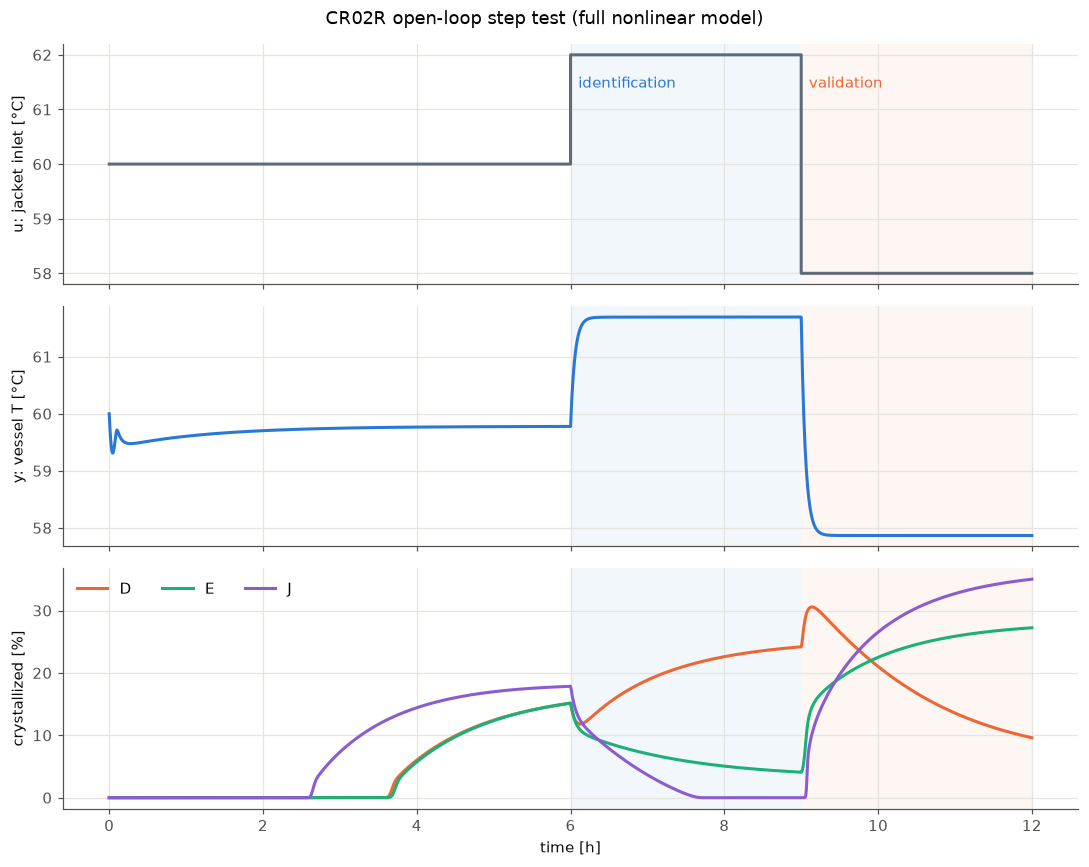

In [2]:
h = t / 3600
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].step(h, u - 273.15, where="post", color=SLATE)
ax[0].set_ylabel("u: jacket inlet [°C]")
ax[1].plot(h, T - 273.15, color=BLUE)
ax[1].set_ylabel("y: vessel T [°C]")
for s, c in (("D", ORANGE), ("E", AQUA), ("J", VIOLET)):
    ax[2].plot(h, 100 * step[f"frac_{s}"], color=c, label=s)
ax[2].set_ylabel("crystallized [%]"); ax[2].set_xlabel("time [h]")
ax[2].legend(ncol=3)
for a in ax:
    a.axvspan(t1 / 3600, t2 / 3600, color=BLUE, alpha=0.06, lw=0)
    a.axvspan(t2 / 3600, h[-1], color=ORANGE, alpha=0.06, lw=0)
ax[0].text(t1 / 3600 + 0.1, u.max() - 273.15 - 0.6, "identification", color=BLUE)
ax[0].text(t2 / 3600 + 0.1, u.max() - 273.15 - 0.6, "validation", color=ORANGE)
fig.suptitle("CR02R open-loop step test (full nonlinear model)")
fig.tight_layout()

i1 = int(np.searchsorted(t, t1)); i2 = int(np.searchsorted(t, t2))
last_hour = (t > t1 - 3600) & (t <= t1)
drift = np.polyfit(t[last_hour], T[last_hour], 1)[0] * 3600
print(f"Operating point: u0 = {u[i1 - 1] - 273.15:.2f} °C, y0 = {T[i1 - 1] - 273.15:.3f} °C")
print(f"Drift in the hour before the step: {drift * 1e3:.2f} mK/h "
      f"(compare with the {du:g} K step: the plant is settled)")

## 2. Deviation variables and fitting $G(s)$

Linear models describe deviations from an operating point:
$\bar u = u - u_0$, $\bar y = y - y_0$, taken at the instant just before the
first step. Four candidate models are fitted by least squares to
$\bar y(t)$ over the identification window:

| Model | $G(s)$ | Parameters |
|---|---|---|
| FO | $\dfrac{K}{\tau s + 1}$ | $K, \tau$ |
| FOPDT | $\dfrac{K e^{-\theta s}}{\tau s + 1}$ | $K, \tau, \theta$ |
| SOPDT | $\dfrac{K e^{-\theta s}}{(\tau_1 s+1)(\tau_2 s+1)}$ | $K, \tau_1, \tau_2, \theta$ |
| Lead-lag | $\dfrac{K(\tau_a s + 1)}{(\tau_1 s+1)(\tau_2 s+1)}$ | $K, \tau_1, \tau_2, \tau_a$ |

The steady-state gain $K$ is in K of vessel temperature per K of jacket
inlet temperature. Models with different numbers of parameters are compared
with the Akaike information criterion,
$\mathrm{AIC} = N \ln(\mathrm{SSE}/N) + 2p$: lower is better, and it
penalises extra parameters.

**No drift correction.** The remaining pre-step creep (3.6 mK/h) is the
tail of the start-up and decays, so subtracting a linear trend would
distort the data rather than clean it: it doubles the first-order fit
error. Over the 3 h window the creep is worth a few mK, small next to
the ~1.9 K response.

In [3]:
u0, y0 = u[i1 - 1], T[i1 - 1]
tid = t[i1:i2 + 1] - t1            # time since the identification step [s]
yid = T[i1:i2 + 1] - y0            # deviation response [K]


def step_response(num, den, theta, tt, amp=1.0):
    # Response of K*num/den * e^(-theta s) to a step of size amp at tt = 0.
    _, ys = signal.step((num, den), T=tt)
    return amp * np.interp(tt - theta, tt, ys, left=0.0)


MODELS = {
    # name: (parameter names, builder -> (num, den, theta))
    "FO": (("K", "tau"),
           lambda K, tau: ([K], [tau, 1.0], 0.0)),
    "FOPDT": (("K", "tau", "theta"),
              lambda K, tau, th: ([K], [tau, 1.0], th)),
    "SOPDT": (("K", "tau1", "tau2", "theta"),
              lambda K, t1_, t2_, th: ([K], np.polymul([t1_, 1], [t2_, 1]), th)),
    "Lead-lag": (("K", "tau1", "tau2", "tau_a"),
                 lambda K, t1_, t2_, ta: (np.polymul([K], [ta, 1.0]),
                                          np.polymul([t1_, 1], [t2_, 1]), 0.0)),
}

# Starting guesses from the data.
K0 = yid[-1] / du
tau63 = tid[np.argmax(yid >= 0.632 * yid[-1])]
GUESS = {"FO": [K0, tau63], "FOPDT": [K0, tau63, 5.0],
         "SOPDT": [K0, tau63, tau63 / 10, 5.0],
         "Lead-lag": [K0, 10 * tau63, tau63, 5 * tau63]}
BOUNDS = {"K": (-10, 10), "tau": (1, 1e6), "tau1": (1, 1e6), "tau2": (1, 1e6),
          "theta": (0, 3600), "tau_a": (-1e6, 1e6)}

fits = {}
for name, (pnames, build) in MODELS.items():
    lo, hi = zip(*(BOUNDS[p] for p in pnames))
    res = optimize.least_squares(
        lambda p: step_response(*build(*p), tid, du) - yid,
        GUESS[name], bounds=(lo, hi), x_scale="jac")
    sse = float(np.sum(res.fun ** 2)); N = tid.size
    fits[name] = dict(p=dict(zip(pnames, res.x)), build=build,
                      tf=build(*res.x), rmse=np.sqrt(sse / N),
                      aic=N * np.log(sse / N) + 2 * len(pnames))

print(f"{'model':<9} {'RMSE [mK]':>10} {'AIC':>9}   parameters (times in s)")
for name, f in fits.items():
    pars = ", ".join(f"{k} = {v:.4g}" for k, v in f["p"].items())
    print(f"{name:<9} {1e3 * f['rmse']:>10.3f} {f['aic']:>9.0f}   {pars}")

model      RMSE [mK]       AIC   parameters (times in s)
FO             0.608     -5342   K = 0.9583, tau = 201.2
FOPDT          0.607     -5342   K = 0.9583, tau = 201.2, theta = 0.05702
SOPDT          0.802     -5139   K = 0.9583, tau1 = 200.2, tau2 = 1, theta = 3.479e-16
Lead-lag       0.176     -6236   K = 0.9588, tau1 = 5148, tau2 = 200.8, tau_a = 5141


### The classical graphical method

For comparison, here is the textbook way to get an FOPDT from a step
response (Smith's two-point method). Read off the times at which the
response reaches 28.3 % and 63.2 % of its final change. Then
$\tau = 1.5\,(t_{63} - t_{28})$ and $\theta = t_{63} - \tau$.

Smith: K = 0.9578, tau = 200.8 s, theta = 0.5 s, RMSE = 1.192 mK


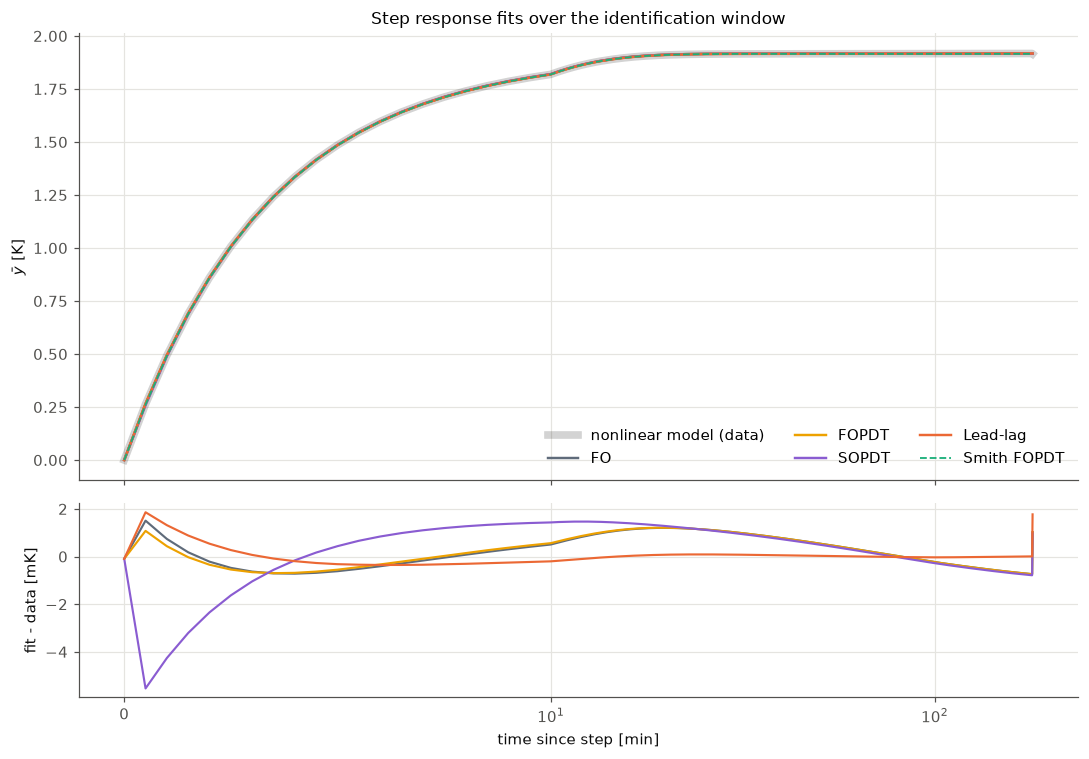

In [4]:
frac = yid / yid[-1]
t28 = np.interp(0.283, frac, tid); t63 = np.interp(0.632, frac, tid)
tau_s = 1.5 * (t63 - t28); th_s = max(t63 - tau_s, 0.0); K_s = yid[-1] / du
y_smith = step_response([K_s], [tau_s, 1], th_s, tid, du)
print(f"Smith: K = {K_s:.4f}, tau = {tau_s:.1f} s, theta = {th_s:.1f} s, "
      f"RMSE = {1e3 * np.sqrt(np.mean((y_smith - yid) ** 2)):.3f} mK")

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                       gridspec_kw=dict(height_ratios=(3, 1.3)))
ax[0].plot(tid / 60, yid, color=INK, lw=5, alpha=0.18, label="nonlinear model (data)")
styles = {"FO": SLATE, "FOPDT": YELLOW, "SOPDT": VIOLET, "Lead-lag": ORANGE}
for name, f in fits.items():
    yf = step_response(*f["tf"], tid, du)
    ax[0].plot(tid / 60, yf, color=styles[name], lw=1.6, label=name)
    ax[1].plot(tid / 60, 1e3 * (yf - yid), color=styles[name], lw=1.4)
ax[0].plot(tid / 60, y_smith, color=AQUA, lw=1.2, ls="--", label="Smith FOPDT")
ax[0].set_ylabel(r"$\bar y$ [K]"); ax[0].legend(ncol=3)
ax[1].set_ylabel("fit - data [mK]"); ax[1].set_xlabel("time since step [min]")
ax[0].set_title("Step response fits over the identification window")
ax[0].set_xscale("symlog", linthresh=10); ax[1].set_xscale("symlog", linthresh=10)
fig.tight_layout()

The time axis is logarithmic above 10 min, so the first seconds and the
last hours can both be seen.

**The plant is first order to a very good approximation.**
- One lag of $\tau \approx 200$ s fits the 2 K step to well under 1 mK.
- The FOPDT fit puts the delay at a fraction of a second: PharmaPy's
  jacket is algebraic, so there is no transport delay.
- The SOPDT fit's second time constant collapses to its lower bound, so the
  data gives no evidence of a second lag.
- The lead-lag model gets its lower AIC from a pole and a zero at about
  $5000$ s that nearly cancel. That is a slow creep worth about 0.1 % of
  the gain, from the reaction and crystal population re-settling at the new
  temperature.

**A first-principles check.** The vessel's energy balance, linearized,
is a first-order lag,
$$\tau = \frac{m c_p}{UA + \dot m c_p}, \qquad K = \frac{UA}{UA + \dot m c_p},
\qquad\text{so}\qquad \tau = K\,\tau_{ht},\quad \tau_{ht} = \frac{m c_p}{UA}.$$
Here $\dot m c_p$ is the heat capacity flow of the feed. PharmaPy reports
$\tau_{ht}$ (it sets the default $T_i$). Then $K\tau_{ht}$ should match the
fitted $\tau$, and the next cell checks it.

In [5]:
tau_ht = float(cl["tau_ht"])
print(f"tau_ht = m cp / UA      = {tau_ht:.1f} s   (from PharmaPy's controller)")
print(f"K * tau_ht              = {fits['FO']['p']['K'] * tau_ht:.1f} s")
print(f"fitted first-order tau  = {fits['FO']['p']['tau']:.1f} s")
print("The remaining few % comes from the reaction heat's temperature dependence "
      "and the finite coolant flow, which the two-line estimate leaves out.")

tau_ht = m cp / UA      = 217.1 s   (from PharmaPy's controller)
K * tau_ht              = 208.1 s
fitted first-order tau  = 201.2 s
The remaining few % comes from the reaction heat's temperature dependence and the finite coolant flow, which the two-line estimate leaves out.


### Validation on the second step

Each fitted $G(s)$ is now driven with the whole input sequence from 6 h on
(+2 K, then −4 K at 9 h), using `scipy.signal.lsim`, and compared with the
nonlinear model on the validation window, which none of them saw. If the
plant were exactly linear, the response to the −4 K step would be exactly
−2 times the response to the +2 K step.

model      ident RMSE [mK]  valid RMSE [mK]
FO                   0.608            4.977
FOPDT                0.607            4.980
SOPDT                0.802            5.148
Lead-lag             0.176            4.226

Gain from the +2 K step:   0.9587 K/K
Gain from the -4 K step:   0.9571 K/K

Best on validation: Lead-lag


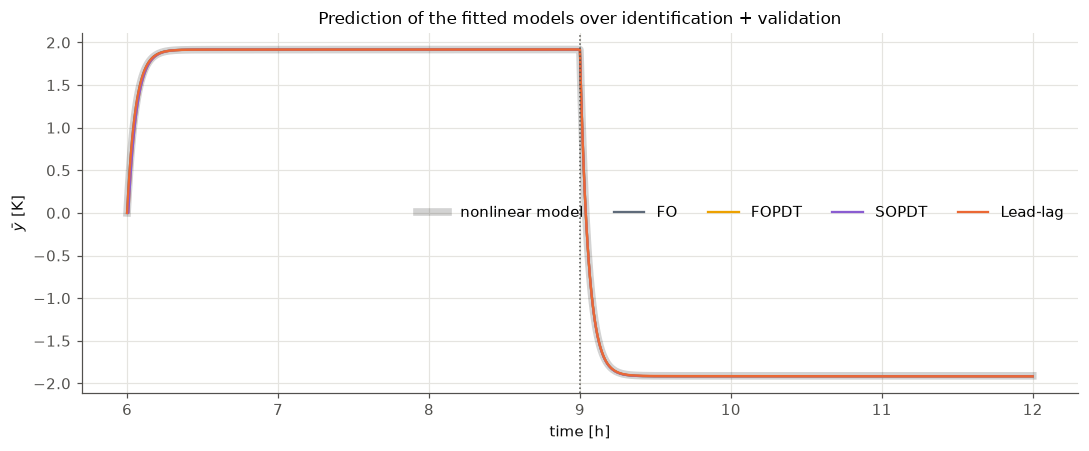

In [6]:
tv = t[i1:] - t1
ubar = u[i1:] - u0


def simulate(num, den, theta, tt, ub):
    # lsim with an input delayed by theta.
    ub_delayed = np.interp(tt - theta, tt, ub, left=0.0)
    # interp=False holds each input sample (zero-order hold). The default
    # linear interpolation would start every step half a sample (15 s) early,
    # which on a 200 s lag is a ~0.3 K error right after the step.
    _, yy, _ = signal.lsim((num, den), ub_delayed, tt, interp=False)
    return yy


val = tv >= (t2 - t1)
yv = T[i1:] - y0
print(f"{'model':<9} {'ident RMSE [mK]':>16} {'valid RMSE [mK]':>16}")
preds = {}
for name, f in fits.items():
    preds[name] = simulate(*f["tf"], tv, ubar)
    rmse_v = np.sqrt(np.mean((preds[name][val] - yv[val]) ** 2))
    f["rmse_val"] = rmse_v
    print(f"{name:<9} {1e3 * f['rmse']:>16.3f} {1e3 * rmse_v:>16.3f}")

# How linear is the plant? Gain seen by each step.
ym_end1 = yv[i2 - i1 - 1]
ym_end2 = yv[-1]
print(f"\nGain from the +2 K step:   {ym_end1 / du:.4f} K/K")
print(f"Gain from the -4 K step:   {(ym_end2 - ym_end1) / (-2 * du):.4f} K/K")

best = min(fits, key=lambda n: fits[n]["rmse_val"])
print(f"\nBest on validation: {best}")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(tv / 3600 + t1 / 3600, yv, color=INK, lw=5, alpha=0.18,
        label="nonlinear model")
for name in fits:
    ax.plot(tv / 3600 + t1 / 3600, preds[name], color=styles[name], lw=1.5,
            label=name)
ax.axvline(t2 / 3600, color=MUTED, lw=1, ls=":")
ax.set_xlabel("time [h]"); ax.set_ylabel(r"$\bar y$ [K]")
ax.set_title("Prediction of the fitted models over identification + validation")
ax.legend(ncol=5)
fig.tight_layout()

## 3. State space

### 3a. A realization of the fitted $G(s)$

Any proper rational $G(s)$ can be written as an LTI state-space system
$$\dot x = A x + B \bar u, \qquad \bar y = C x + D \bar u .$$
`scipy.signal.tf2ss` returns the controllable canonical form. The poles of
$G$ are the eigenvalues of $A$. Because the realization is minimal, the
controllability matrix $[B,\ AB]$ and the observability matrix
$[C;\ CA]$ both have full rank.

In [7]:
LL = fits["Lead-lag"]
num_g, den_g, _ = LL["tf"]
A2, B2, C2, D2 = signal.tf2ss(num_g, den_g)
np.set_printoptions(precision=4, suppress=False)
print("A =\n", A2, "\nB =\n", B2, "\nC =", C2, "  D =", D2)
poles = np.linalg.eigvals(A2)
print("\npoles (eig A):", poles, "1/s  ->  time constants", -1 / poles, "s")
ctrb = np.hstack([B2, A2 @ B2]); obsv = np.vstack([C2, C2 @ A2])
print("rank controllability =", np.linalg.matrix_rank(ctrb),
      " rank observability =", np.linalg.matrix_rank(obsv))
print("zero:", np.roots(num_g), "1/s   DC gain C(-A)^-1 B + D =",
      (C2 @ np.linalg.solve(-A2, B2) + D2).item())
print("stable (all Re < 0):", bool(np.all(poles.real < 0)))
sv_o = np.linalg.svd(obsv / np.linalg.norm(obsv), compute_uv=False)
print(f"singular values of the scaled observability matrix: {sv_o}")
p_slow = poles[np.argmin(np.abs(poles))].real
print(f"slow pole {p_slow:.4e}, zero {np.roots(num_g)[0]:.4e} 1/s")

A =
 [[-5.1755e-03 -9.6754e-07]
 [ 1.0000e+00  0.0000e+00]] 
B =
 [[1.]
 [0.]] 
C = [[4.7693e-03 9.2771e-07]]   D = [[0.]]

poles (eig A): [-0.005 +0.j -0.0002+0.j] 1/s  ->  time constants [ 200.751 -0.j 5148.4341-0.j] s
rank controllability = 2  rank observability = 2
zero: [-0.0002] 1/s   DC gain C(-A)^-1 B + D = 0.958840366764599
stable (all Re < 0): True
singular values of the scaled observability matrix: [1.0000e+00 1.3576e-09]
slow pole -1.9423e-04, zero -1.9452e-04 1/s


The slow pole and the zero almost coincide. Mathematically the realization
is minimal (both ranks are 2), but the slow mode is *nearly*
unobservable: the observability matrix is close to rank 1. That is the
state-space view of the conclusion in section 2: one state, the
heat-transfer lag, does nearly all the work.

### 3b. The exact linearization of the full model

`CR02R_plant_id.py` linearized PharmaPy's own right-hand side
$\dot x = f(x, u)$ at the pre-step operating point $(x_0, u_0)$, by central
finite differences:

$$A = \left.\frac{\partial f}{\partial x}\right|_{x_0,u_0}, \quad
  B = \left.\frac{\partial f}{\partial u}\right|_{x_0,u_0}, \quad
  C = e_T^\top \;(\text{picks out } T), \quad D = 0 .$$

The state vector has every species mass in the liquid, the temperature, the
level-loop integral, and every bin of the four population balances. This
is the model the step test was approximating. The plant is **locally
asymptotically stable** if every eigenvalue of $A$ has a negative real part.

An eigenvalue only matters to the temperature loop if its mode is both
excited by $u$ and seen in $y$, that is, if it is a pole of
$G(s) = C(sI-A)^{-1}B$. The **PBH test** measures both for each mode
$\lambda_k$, using its left and right eigenvectors $w_k$ and $v_k$:
$|w_k^H B|$ for controllability and $|C v_k|$ for observability. Their
product, relative to the largest, ranks the modes by how much they matter
for $u \to y$.

818 states. max Re(lambda) = 4.436e-04 1/s, min Re(lambda) = -4.555e+00 1/s
Eigenvalues with Re > 0: 9; their largest relative PBH measure is 1.2e-07
Modes with relative PBH > 1e-5: 5; max Re among them = -4.988e-03 1/s -> input-output stable: True
Stiffness ratio of the stable modes |Re|max / |Re|min = 3.48e+04
Complex eigenvalues: 762

DC gain of the full model  -C A^-1 B = 0.9572 K/K
DC gain of the fitted lead-lag       = 0.9588 K/K

states: liquid0.mass_j: 12, global_temp: 1, solid0.distrib: 501, solid1.distrib: 101, solid2.distrib: 101, solid3.distrib: 101, level_integral: 1

The right-half-plane eigenvalues and where they live:
  +4.44e-04 1/s (doubling    26 min), PBH 1e-07, states [np.str_('solid2.distrib[13]'), np.str_('solid2.distrib[14]'), np.str_('solid2.distrib[12]')]
  +4.07e-04 1/s (doubling    28 min), PBH 1e-07, states [np.str_('solid2.distrib[13]'), np.str_('solid2.distrib[14]'), np.str_('solid2.distrib[12]')]
  +3.83e-04 1/s (doubling    30 min), PBH 1e-08, states [n

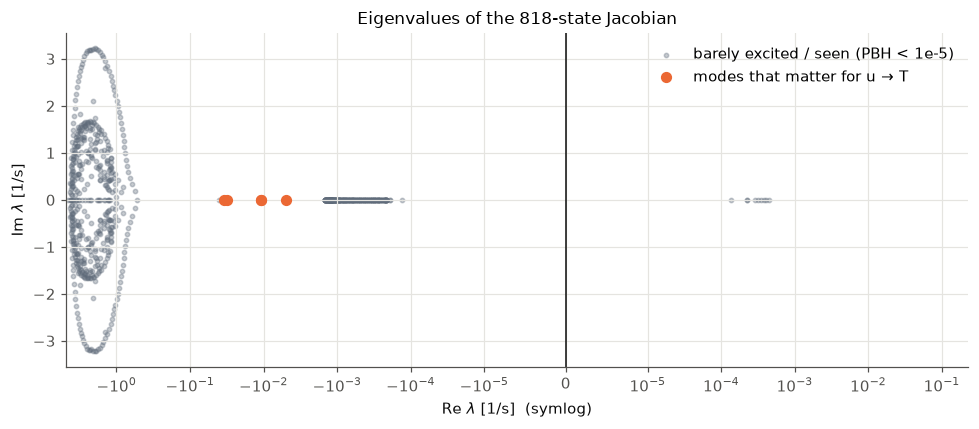

In [8]:
A, B, C = lin["A"], lin["B"], lin["C"]
labels = list(lin["labels"]); n = A.shape[0]
lam, WL, VR = linalg.eig(A, left=True, right=True)
# PBH (Popov-Belevitch-Hautus) measures per mode, on unit eigenvectors:
# how strongly u excites the mode (|w^H B|) and how strongly y sees it (|C v|).
ctrb_k = np.abs(WL.conj().T @ B).ravel() / (np.linalg.norm(WL, axis=0) * np.linalg.norm(B))
obsv_k = np.abs(C @ VR).ravel() / (np.linalg.norm(C) * np.linalg.norm(VR, axis=0))
pbh = ctrb_k * obsv_k / (ctrb_k * obsv_k).max()
visible = pbh > 1e-5
print(f"{n} states. max Re(lambda) = {lam.real.max():.3e} 1/s, "
      f"min Re(lambda) = {lam.real.min():.3e} 1/s")
print(f"Eigenvalues with Re > 0: {(lam.real > 0).sum()}; their largest relative PBH "
      f"measure is {pbh[lam.real > 0].max():.1e}")
print(f"Modes with relative PBH > 1e-5: {visible.sum()}; max Re among them = "
      f"{lam[visible].real.max():.3e} 1/s -> input-output stable: "
      f"{bool(np.all(lam[visible].real < 0))}")
stable_re = lam.real[lam.real < 0]
print(f"Stiffness ratio of the stable modes |Re|max / |Re|min = "
      f"{stable_re.min() / stable_re.max():.2e}")
print(f"Complex eigenvalues: {(np.abs(lam.imag) > 1e-12).sum()}")
G0_full = (C @ np.linalg.solve(-A, B)).item()
print(f"\nDC gain of the full model  -C A^-1 B = {G0_full:.4f} K/K")
print(f"DC gain of the fitted lead-lag       = {LL['p']['K']:.4f} K/K")

# Which states are there?
groups = {}
for l in labels:
    groups[l.split("[")[0]] = groups.get(l.split("[")[0], 0) + 1
print("\nstates:", ", ".join(f"{k}: {v}" for k, v in groups.items()))

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(lam[~visible].real, lam[~visible].imag, s=8, color=SLATE, alpha=0.35,
           label="barely excited / seen (PBH < 1e-5)")
ax.scatter(lam[visible].real, lam[visible].imag, s=40, color=ORANGE, zorder=3,
           label="modes that matter for u → T")
ax.axvline(0, color=INK, lw=1)
ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlabel(r"Re $\lambda$ [1/s]  (symlog)"); ax.set_ylabel(r"Im $\lambda$ [1/s]")
ax.legend(); ax.set_title(f"Eigenvalues of the {n}-state Jacobian")
fig.tight_layout()

print("\nThe right-half-plane eigenvalues and where they live:")
for k in np.argsort(-lam.real)[:(lam.real > 0).sum()]:
    top = np.argsort(-np.abs(VR[:, k]))[:3]
    print(f"  {lam[k].real:+.2e} 1/s (doubling {np.log(2) / lam[k].real / 60:5.0f} min), "
          f"PBH {pbh[k]:.0e}, states {[labels[i] for i in top]}")

**What the right-half-plane eigenvalues are.** They sit only on the leading
edge of the product crystal size distributions (D, E, J), around bins
11–14, where the number density drops by three orders of magnitude from one
bin to the next. Two things cause them, and neither is a real instability
of the plant:

- The operating point is not perfectly stationary there. At 6 h the
  crystal fronts are still creeping out, so $f(x_0) \neq 0$ in those bins.
- The finite-volume growth term uses a second-order upwind reconstruction
  with PharmaPy's default van Leer flux limiter. The limiter is not smooth
  where the slope ratio crosses zero, which happens at a steep front, so a
  finite-difference Jacobian taken there can have small positive diagonal
  terms. (`OneDFVMMechanism(limiter="van_albada")` is the smooth
  alternative.)

Their PBH measures are about $10^{-7}$ of the dominant mode's, so the jacket
barely excites them and the temperature barely sees them. Feedback from $T$ to $u$ cannot
move them either, which is why they reappear unchanged in the closed loop.
For the temperature loop the plant behaves as a stable system, and the
nonlinear simulation confirms it: the distributions stay bounded.

### 3c. Which eigenvalues matter?

Splitting $G(s)$ into a sum of modal residues,
$\sum_i r_i/(s-\lambda_i)$, would be the textbook answer. It fails here
because $A$ is strongly *non-normal*: growth in a size coordinate is an
advection, which couples neighbouring bins into near-defective chains, and
the eigenvector matrix has a condition number around $10^{31}$. The
individual residues are then pure round-off, and the PBH ranking is the
reliable tool.

There is also a direct shortcut. The temperature row of $A$ alone gives a
one-state model, $\dot{\bar T} \approx A_{TT}\,\bar T + B_T\,\bar u$.

In [9]:
print(f"cond(V) = {np.linalg.cond(VR):.1e}  (why modal residues are meaningless here)\n")
print(f"{'rank':>4} {'lambda [1/s]':>24} {'tau [s]':>9} {'PBH (rel.)':>11}")
for rank, k in enumerate(np.argsort(-pbh)[:6], 1):
    print(f"{rank:>4} {lam[k].real:>13.4e}{lam[k].imag:+.2e}j {-1 / lam[k].real:>9.1f} {pbh[k]:>11.1e}")

i_T = int(lin["i_temp"])
A_TT, B_T = A[i_T, i_T], B[i_T, 0]
k_dom = int(np.argmax(pbh))
print(f"\ndominant mode (PBH):        tau = {-1 / lam[k_dom].real:7.1f} s")
print(f"temperature row only:       tau = -1/A_TT = {-1 / A_TT:7.1f} s,  K = -B_T/A_TT = {-B_T / A_TT:.4f}")
print(f"fitted first-order model:   tau = {fits['FO']['p']['tau']:7.1f} s,  K = {fits['FO']['p']['K']:.4f}")
print(f"full model DC gain:                                 K = {G0_full:.4f}")

cond(V) = 1.5e+31  (why modal residues are meaningless here)

rank             lambda [1/s]   tau [s]  PBH (rel.)
   1   -4.9881e-03+0.00e+00j     200.5     1.0e+00
   2   -1.0715e-02+0.00e+00j      93.3     1.1e-04
   3   -1.0775e-02+0.00e+00j      92.8     1.1e-04
   4   -3.1143e-02+0.00e+00j      32.1     6.1e-05
   5   -3.4495e-02+0.00e+00j      29.0     1.6e-05
   6   -5.6546e-04+4.75e-04j    1768.5     1.7e-06

dominant mode (PBH):        tau =   200.5 s
temperature row only:       tau = -1/A_TT =   200.4 s,  K = -B_T/A_TT = 0.9568
fitted first-order model:   tau =   201.2 s,  K = 0.9583
full model DC gain:                                 K = 0.9572


### 3d. Three models side by side

Here the step response of the full linear model (818 states) is compared
with the fitted lead-lag (2 states), the fitted first-order model (1 state)
and the nonlinear model itself, over the identification step.

The fitted models come out *closer* to the nonlinear data than the exact
linearization does. That is expected. The fits were tuned to this very
step, while the Jacobian is taken at a point that is still creeping
($f(x_0) \neq 0$) and is valid only for infinitesimal steps.
All three agree to a few mK on a 1.9 K response.

RMSE full linearization vs nonlinear: 2.176 mK
RMSE fitted lead-lag vs nonlinear:    0.176 mK
RMSE fitted first order vs nonlinear: 0.608 mK


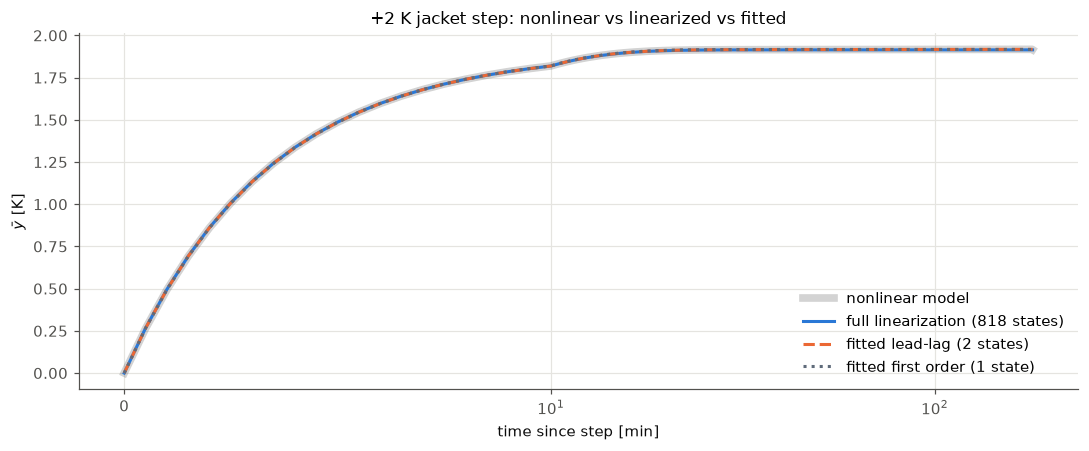

In [10]:
full = signal.StateSpace(A, B, C, np.zeros((1, 1)))
_, y_full, _ = signal.lsim(full, np.full_like(tid, du), tid)
y_ll = step_response(*LL["tf"], tid, du)
y_fo = step_response(*fits["FO"]["tf"], tid, du)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(tid / 60, yid, color=INK, lw=5, alpha=0.18, label="nonlinear model")
ax.plot(tid / 60, y_full, color=BLUE, label=f"full linearization ({n} states)")
ax.plot(tid / 60, y_ll, color=ORANGE, ls="--", label="fitted lead-lag (2 states)")
ax.plot(tid / 60, y_fo, color=SLATE, ls=":", label="fitted first order (1 state)")
ax.set_xscale("symlog", linthresh=10)
ax.set_xlabel("time since step [min]"); ax.set_ylabel(r"$\bar y$ [K]")
ax.legend(); ax.set_title("+2 K jacket step: nonlinear vs linearized vs fitted")
fig.tight_layout()
print(f"RMSE full linearization vs nonlinear: {1e3 * np.sqrt(np.mean((y_full - yid) ** 2)):.3f} mK")
print(f"RMSE fitted lead-lag vs nonlinear:    {1e3 * np.sqrt(np.mean((y_ll - yid) ** 2)):.3f} mK")
print(f"RMSE fitted first order vs nonlinear: {1e3 * np.sqrt(np.mean((y_fo - yid) ** 2)):.3f} mK")

## 4. Frequency response (Bode)

For any LTI system, a sinusoidal input $\bar u = \sin\omega t$ gives, at
steady state, $\bar y = |G(j\omega)|\sin(\omega t + \angle G(j\omega))$.
The full model's frequency response is evaluated directly as
$C(j\omega I - A)^{-1}B$.

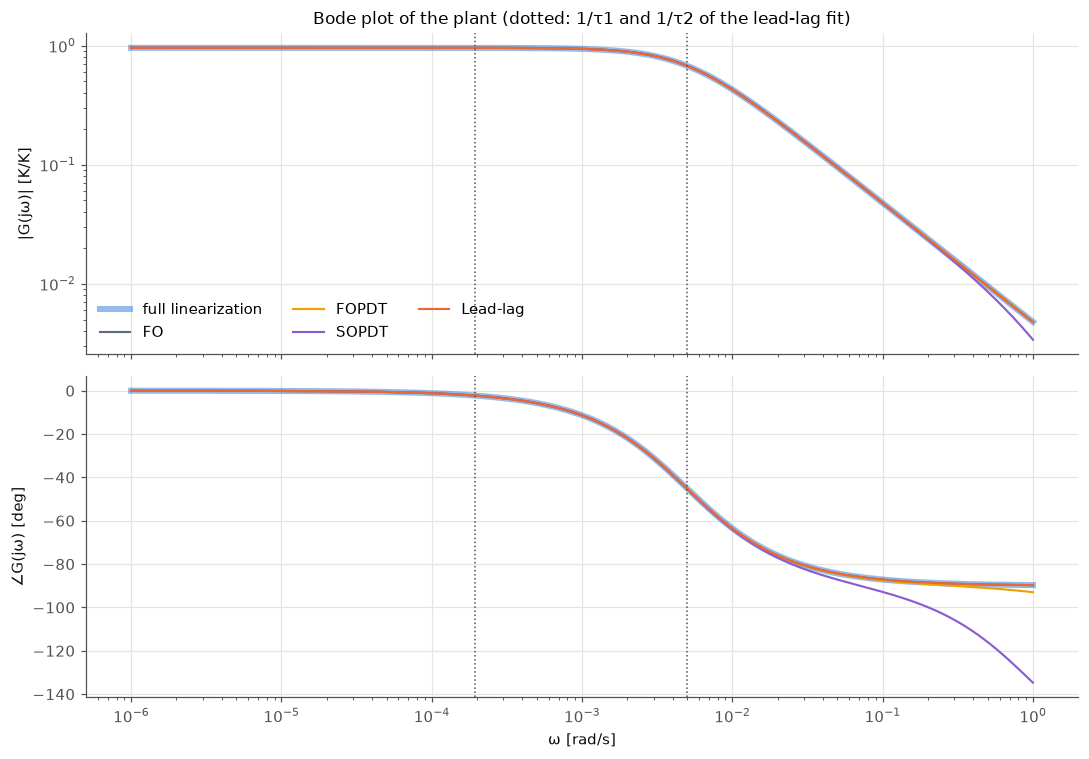

In [11]:
wgrid = np.logspace(-6, 0, 300)


def freq_full(Am, Bm, Cm, ww):
    eye = np.eye(Am.shape[0])
    return np.array([(Cm @ np.linalg.solve(1j * wk * eye - Am, Bm)).item() for wk in ww])


def freq_tf(num, den, theta, ww):
    return signal.freqs(num, den, worN=ww)[1] * np.exp(-1j * ww * theta)


G_full_w = freq_full(A, B, C, wgrid)
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].loglog(wgrid, np.abs(G_full_w), color=BLUE, lw=4, alpha=0.5, label="full linearization")
ax[1].semilogx(wgrid, np.degrees(np.unwrap(np.angle(G_full_w))), color=BLUE, lw=4, alpha=0.5)
for name, f in fits.items():
    Gw = freq_tf(*f["tf"], wgrid)
    ax[0].loglog(wgrid, np.abs(Gw), color=styles[name], lw=1.4, label=name)
    ax[1].semilogx(wgrid, np.degrees(np.unwrap(np.angle(Gw))), color=styles[name], lw=1.4)
for p in (LL["p"]["tau1"], LL["p"]["tau2"]):
    for a in ax:
        a.axvline(1 / p, color=MUTED, lw=1, ls=":")
ax[0].set_ylabel("|G(jω)| [K/K]"); ax[1].set_ylabel("∠G(jω) [deg]")
ax[1].set_xlabel("ω [rad/s]"); ax[0].legend(ncol=3)
ax[0].set_title("Bode plot of the plant (dotted: 1/τ1 and 1/τ2 of the lead-lag fit)")
fig.tight_layout()

## 5. Feedback: PharmaPy's PI jacket loop

`JacketPIDContinuousVesselController` (as used in `CR02R_control.py`) sets
$$u = r + K_c\left(e + \frac{1}{T_i}\int e\,dt\right), \qquad e = r - y .$$
The set point $r$ is the *bias*, which works as a feedforward term. With
default tuning, $K_c = 1/0.25 = 4$ and $T_i = \tau_{ht} = m c_p/(UA)$, which
is IMC tuning for a first-order plant. In the Laplace domain this is a
two-degree-of-freedom controller:
$$U = R + C(s)\,(R - Y), \qquad C(s) = K_c\,\frac{T_i s + 1}{T_i s},$$
so
$$\frac{Y}{R} = \frac{G(1 + C)}{1 + GC}, \qquad L(s) = G(s)C(s) .$$
**Stability is decided by $L$ alone**, through the roots of $1 + L(s) = 0$.

In [12]:
Kc, Ti = float(cl["kc"]), float(cl["ti"])
print(f"PharmaPy default tuning on CR02R: Kc = {Kc:g} K/K, Ti = tau_ht = {Ti:.1f} s")
num_c, den_c = [Kc * Ti, Kc], [Ti, 0.0]
num_L = np.polymul(num_g, num_c); den_L = np.polymul(den_g, den_c)

PharmaPy default tuning on CR02R: Kc = 4 K/K, Ti = tau_ht = 217.1 s


### Nyquist plot and stability margins

The Nyquist criterion says $Z = N + P$. $P$ is the number of open-loop
poles of $L$ in the right half-plane: here 0. The plant's poles (the modes
visible in $G$) are all stable, and the PI integrator sits at the origin,
which the contour skirts. $N$ is the
number of clockwise encirclements of $-1$ by $L(j\omega)$. $Z$ is the
number of unstable closed-loop poles. So the loop is stable if and only if
the curve does not encircle $-1$.

- **Gain margin:** $1/|L|$ where $\angle L = -180°$.
- **Phase margin:** $180° + \angle L$ where $|L| = 1$ (the crossover $\omega_c$).
- **Delay margin:** the extra pure delay the loop tolerates, $\mathrm{PM}/\omega_c$.
- **$M_s$:** $\max|1/(1+L)|$, the inverse of the closest approach to $-1$.
  Values of 1.2–2 are considered robust.

    fitted lead-lag: crossover 0.0190 rad/s, PM = 91.1°, delay margin = 84 s, GM = infinite (phase never reaches -180°), Ms = 1.000
 full linearization: crossover 0.0190 rad/s, PM = 91.1°, delay margin = 84 s, GM = infinite (phase never reaches -180°), Ms = 1.000


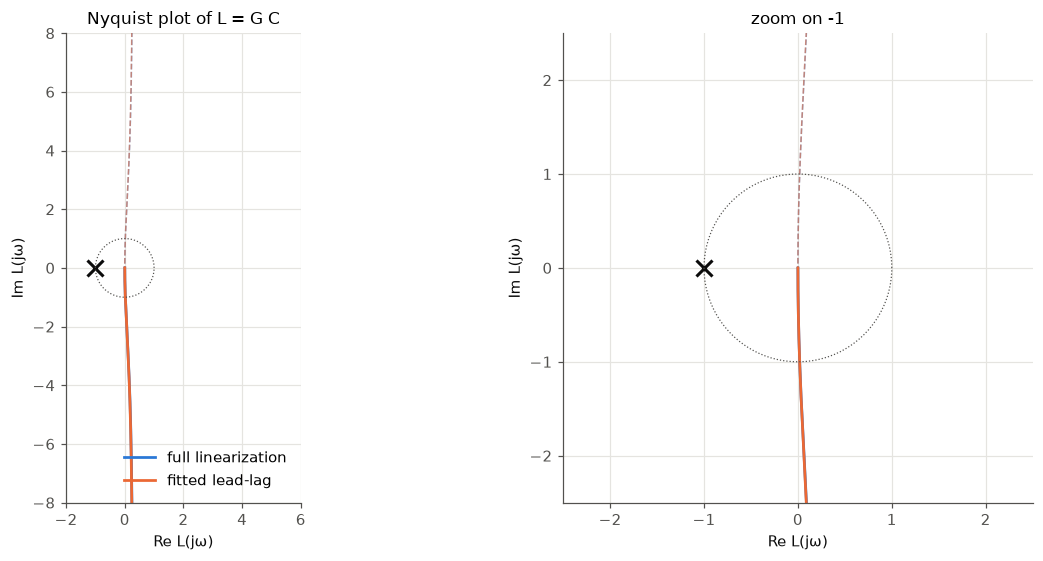

In [13]:
wN = np.logspace(-7, 1, 4000)


def margins(Lw, ww):
    mag, ph = np.abs(Lw), np.unwrap(np.angle(Lw))
    out = {}
    ic = np.where(np.diff(np.sign(mag - 1)))[0]
    if len(ic):
        k = ic[0]; wc = np.interp(0, [mag[k] - 1, mag[k + 1] - 1], ww[k:k + 2])
        pm = 180 + np.degrees(np.interp(wc, ww[k:k + 2], ph[k:k + 2]))
        out.update(wc=wc, pm=pm, dm=np.radians(pm) / wc)
    ip = np.where(np.diff(np.sign(ph + np.pi)))[0]
    if len(ip):
        k = ip[0]; w180 = np.interp(-np.pi, ph[k:k + 2][::-1], ww[k:k + 2][::-1])
        out.update(w180=w180, gm=1 / np.interp(w180, ww, mag))
    out["ms"] = np.max(1 / np.abs(1 + Lw))
    return out


L_fit = freq_tf(num_L, den_L, 0.0, wN)
C_w = Kc * (Ti * 1j * wN + 1) / (Ti * 1j * wN)
L_full = freq_full(A, B, C, wN) * C_w
for name, Lw in (("fitted lead-lag", L_fit), ("full linearization", L_full)):
    m = margins(Lw, wN)
    gm = f"{m['gm']:.2f}" if "gm" in m else "infinite (phase never reaches -180°)"
    print(f"{name:>19}: crossover {m['wc']:.4f} rad/s, PM = {m['pm']:.1f}°, "
          f"delay margin = {m['dm']:.0f} s, GM = {gm}, Ms = {m['ms']:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
for a, lim in zip(ax, (None, 2.5)):
    for Lw, c, lab in ((L_full, BLUE, "full linearization"), (L_fit, ORANGE, "fitted lead-lag")):
        a.plot(Lw.real, Lw.imag, color=c, lw=1.8, label=lab)
        a.plot(Lw.real, -Lw.imag, color=c, lw=1, ls="--", alpha=0.6)
    a.plot(-1, 0, "x", color=INK, ms=10, mew=2)
    th = np.linspace(0, 2 * np.pi, 200)
    a.plot(np.cos(th), np.sin(th), color=MUTED, lw=0.8, ls=":")
    a.set_aspect("equal"); a.set_xlabel("Re L(jω)"); a.set_ylabel("Im L(jω)")
    if lim:
        a.set_xlim(-lim, lim); a.set_ylim(-lim, lim); a.set_title("zoom on -1")
    else:
        a.set_xlim(-2, max(6, Kc * 1.5)); a.set_ylim(-8, 8); a.set_title("Nyquist plot of L = G C")
ax[0].legend(loc="lower right")
fig.tight_layout()

**Why the Nyquist curve is a straight line.** PharmaPy's default puts the
PI zero at $-1/T_i = -1/\tau_{ht}$ (217 s), right on top of the plant pole
($\tau = 201$ s). With the pole and zero cancelling,
$$L(s) = K_c K\,\frac{T_i s + 1}{T_i s\,(\tau s + 1)} \approx \frac{K_c K}{T_i\,s} = \frac{\omega_c}{s},$$
which is a pure integrator. Its Nyquist plot runs down the negative
imaginary axis at a constant phase of −90°. That gives PM ≈ 90°, no −180°
crossing (GM = ∞), and $|1 + L| \ge 1$ everywhere ($M_s = 1$). This is
exactly what IMC tuning aims for, with
$\omega_c = K_c K / T_i \approx 4 \times 0.96 / 217 \approx 0.018$ rad/s.
The delay margin (≈ 84 s) is the real robustness limit: an unmodelled
lag of that size, such as a sensor or a slow jacket, would destabilize
the loop.

### Closed-loop poles

Two independent checks: the roots of $\mathrm{den}_G\,\mathrm{den}_C + \mathrm{num}_G\,\mathrm{num}_C$ for
the fitted model, and the eigenvalues of the closed-loop state matrix for
the full model. For the full model, the PI integral $z = \int e\,dt$ is
added as one more state:
$$\begin{bmatrix}\dot x\\ \dot z\end{bmatrix} =
\underbrace{\begin{bmatrix}A - K_c B C & \tfrac{K_c}{T_i} B\\ -C & 0\end{bmatrix}}_{A_{cl}}
\begin{bmatrix}x\\ z\end{bmatrix} +
\underbrace{\begin{bmatrix}(1 + K_c) B\\ 1\end{bmatrix}}_{B_{cl}} r,
\qquad y = [C\ \ 0]\begin{bmatrix}x\\ z\end{bmatrix}.$$

In [14]:
char = np.polyadd(np.polymul(den_g, den_c), np.polymul(num_g, num_c))
cl_poles_fit = np.roots(char)
Acl = np.block([[A - Kc * B @ C, (Kc / Ti) * B], [-C, np.zeros((1, 1))]])
Bcl = np.vstack([(1 + Kc) * B, [[1.0]]])
Ccl = np.hstack([C, np.zeros((1, 1))])
lam_cl, WLc, VRc = linalg.eig(Acl, left=True, right=True)
pbh_cl = (np.abs(WLc.conj().T @ Bcl).ravel() / np.linalg.norm(WLc, axis=0)) * \
         (np.abs(Ccl @ VRc).ravel() / np.linalg.norm(VRc, axis=0))
pbh_cl /= pbh_cl.max()
print("fitted model, closed-loop poles [1/s]:", np.round(cl_poles_fit, 6))
dom = lam_cl[np.argsort(-pbh_cl)[:3]]
print("full model, dominant closed-loop poles (PBH):", np.round(dom, 6))
rhp_ol = np.sort(lam[lam.real > 0].real); rhp_cl = np.sort(lam_cl[lam_cl.real > 0].real)
same = rhp_ol.size == rhp_cl.size and np.allclose(rhp_ol, rhp_cl, rtol=1e-6)
print(f"crystal-front eigenvalues with Re > 0: {rhp_ol.size} open loop, {rhp_cl.size} closed "
      f"loop, unchanged by feedback: {same}")
print(f"closed loop, modes with relative PBH > 1e-5: max Re = "
      f"{lam_cl[pbh_cl > 1e-5].real.max():.3e} 1/s -> stable: "
      f"{bool(np.all(lam_cl[pbh_cl > 1e-5].real < 0))}")

fitted model, closed-loop poles [1/s]: [-0.0196 -0.0045 -0.0002]
full model, dominant closed-loop poles (PBH): [-0.0196+0.j -0.0045+0.j -0.0311+0.j]
crystal-front eigenvalues with Re > 0: 9 open loop, 9 closed loop, unchanged by feedback: True
closed loop, modes with relative PBH > 1e-5: max Re = -4.488e-03 1/s -> stable: True


Reading the poles:
- **−0.0196 1/s** is the designed closed-loop pole. It sits at
  $\approx \omega_c$, a closed-loop time constant of about 50 s, or
  $\tau_{ht}/4$, which matches PharmaPy's `closed_loop_fraction = 0.25`.
- **−0.0045 1/s** sits almost on the PI zero ($-1/217$).
- **−0.0002 1/s** sits almost on the plant's slow zero.

Poles sitting next to zeros contribute almost nothing to the response. The
full model's dominant closed-loop poles (PBH ranking) are the same, and the
crystal-front eigenvalues stay where they were, since feedback through $T$
cannot reach them.

### Predicted vs simulated closed-loop response

The linear closed-loop models predict the response to the −1 K set-point
step at 6 h. Here they are compared with the nonlinear PharmaPy run that
uses the real controller, including its jacket limits and anti-windup.
The figure also shows the controller output $u$ (jacket inlet temperature).

A phase margin of 90° would normally mean no overshoot. The ~9 % overshoot
here comes from the set point entering $u$ directly as the bias (the
feedforward path in $G(1 + C)/(1 + GC)$). At $t = 0^+$ the jacket jumps by
$(1 + K_c)\,\Delta r = 5\,\Delta r$, and the feedback then has to take back
the excess.

                       overshoot  2% settling
nonlinear (PharmaPy)        8.9%      10.0 min
full linear                 8.9%      10.0 min
fitted lead-lag             8.9%      10.0 min


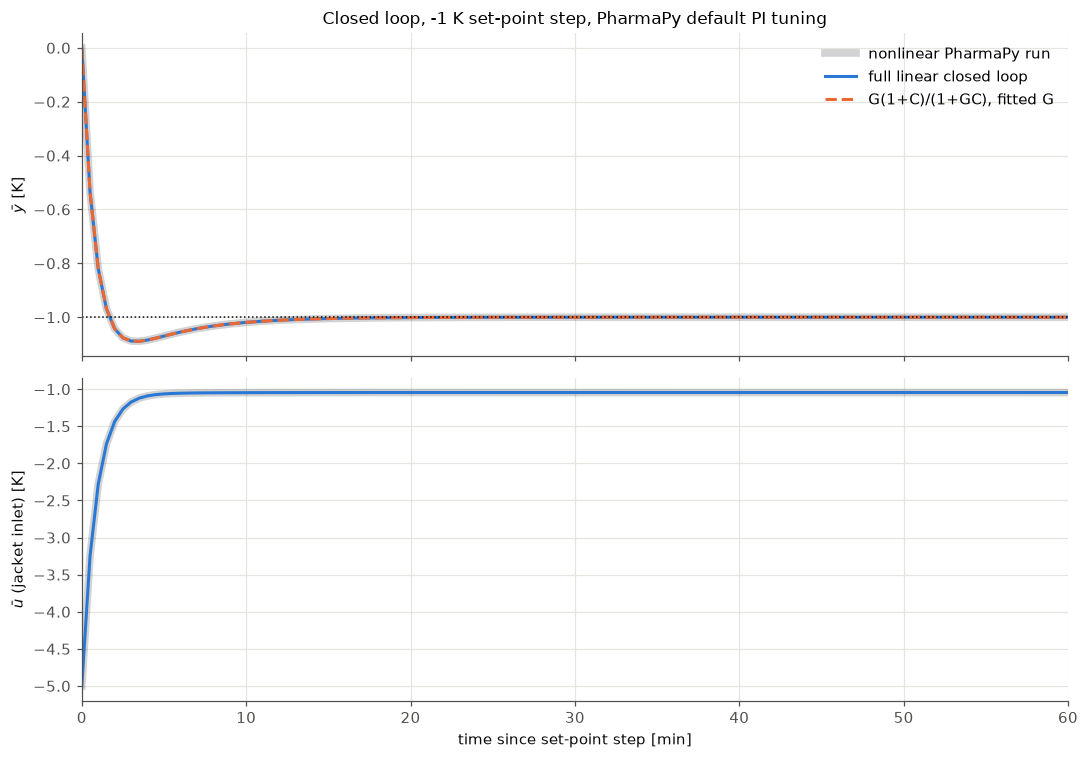

In [15]:
tc = cl["time"]; ts = float(cl["t_step"]); j1 = int(np.searchsorted(tc, ts))
tt = tc[j1:] - ts; dr = float(cl["setpoint"][-1] - cl["setpoint"][j1 - 1])
ycl = cl["temp"][j1:] - cl["temp"][j1 - 1]
ucl = cl["jacket"][j1:] - cl["jacket"][j1 - 1]

_, y_cl_full, x_cl = signal.lsim(signal.StateSpace(Acl, Bcl, Ccl, 0), np.full_like(tt, dr), tt)
u_cl_full = dr * (1 + Kc) - Kc * y_cl_full + (Kc / Ti) * x_cl[:, -1]
T_yr = (np.polymul(num_g, np.polyadd(den_c, num_c)), char)   # G(1+C)/(1+GC)
_, y_cl_fit = signal.step(T_yr, T=tt); y_cl_fit *= dr

def metrics(y):
    os_ = max(0.0, (y.min() - dr) / dr) if dr < 0 else max(0.0, (y.max() - dr) / dr)
    out = np.where(np.abs(y - dr) > 0.02 * abs(dr))[0]
    return os_, (tt[out[-1] + 1] if len(out) and out[-1] + 1 < tt.size else 0.0)

print(f"{'':<22}{'overshoot':>10}{'2% settling':>13}")
for lab, y in (("nonlinear (PharmaPy)", ycl), ("full linear", y_cl_full), ("fitted lead-lag", y_cl_fit)):
    os_, ts_ = metrics(y)
    print(f"{lab:<22}{os_:>10.1%}{ts_ / 60:>10.1f} min")

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(tt / 60, ycl, color=INK, lw=5, alpha=0.18, label="nonlinear PharmaPy run")
ax[0].plot(tt / 60, y_cl_full, color=BLUE, label="full linear closed loop")
ax[0].plot(tt / 60, y_cl_fit, color=ORANGE, ls="--", label="G(1+C)/(1+GC), fitted G")
ax[0].axhline(dr, color=INK, lw=1, ls=":")
ax[0].set_ylabel(r"$\bar y$ [K]"); ax[0].legend()
ax[1].plot(tt / 60, ucl, color=INK, lw=5, alpha=0.18, label="nonlinear PharmaPy run")
ax[1].plot(tt / 60, u_cl_full, color=BLUE, label="full linear")
ax[1].set_ylabel(r"$\bar u$ (jacket inlet) [K]"); ax[1].set_xlabel("time since set-point step [min]")
ax[0].set_xlim(0, 60)
ax[0].set_title("Closed loop, -1 K set-point step, PharmaPy default PI tuning")
fig.tight_layout()

### Root locus over $K_c$

The root locus shows how the closed-loop poles of the fitted model move as
$K_c$ is varied, with $T_i$ fixed at PharmaPy's default. The integrator
pole leaves the origin toward the PI zero at $-1/T_i$. The fast plant pole
and the slow plant pole move toward the plant's zero and toward
$-\infty$ (relative degree 1). With no dead time in the model, no value of
$K_c$ destabilizes it; the margins section shows how much delay it would
take to do so.

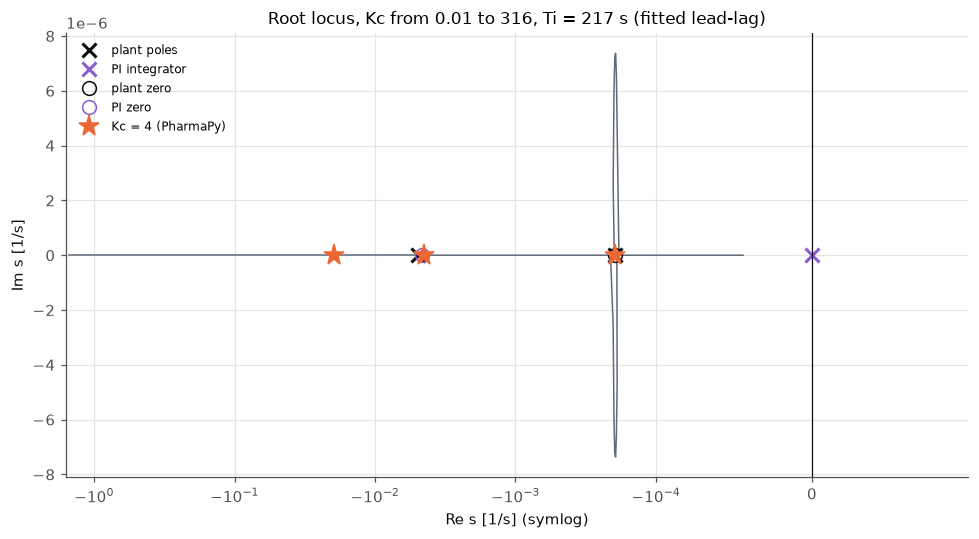

In [16]:
gains = np.logspace(-2, 2.5, 400)
locus = np.array([np.sort_complex(np.roots(np.polyadd(np.polymul(den_g, [Ti, 0]),
                                                      np.polymul(num_g, [k * Ti, k]))))
                  for k in gains])
fig, ax = plt.subplots(figsize=(9, 5))
for j in range(locus.shape[1]):
    ax.plot(locus[:, j].real, locus[:, j].imag, color=SLATE, lw=1)
ax.plot(np.roots(den_g).real, np.roots(den_g).imag, "x", color=INK, ms=9, mew=2, label="plant poles")
ax.plot(0, 0, "x", color=VIOLET, ms=9, mew=2, label="PI integrator")
ax.plot(np.roots(num_g).real, 0 * np.roots(num_g).real, "o", mfc="none", color=INK, ms=9, label="plant zero")
ax.plot(-1 / Ti, 0, "o", mfc="none", color=VIOLET, ms=9, label="PI zero")
ax.plot(cl_poles_fit.real, cl_poles_fit.imag, "*", color=ORANGE, ms=14, label=f"Kc = {Kc:g} (PharmaPy)")
ax.axvline(0, color=INK, lw=0.8)
ax.set_xscale("symlog", linthresh=1e-4)
ax.set_xlim(right=1e-4)
ax.set_xlabel("Re s [1/s] (symlog)"); ax.set_ylabel("Im s [1/s]"); ax.legend(fontsize=8)
ax.set_title(f"Root locus, Kc from 0.01 to {gains[-1]:.0f}, Ti = {Ti:.0f} s (fitted lead-lag)")
fig.tight_layout()

### Alternative tuning from the fitted model (SIMC)

Skogestad's SIMC rules take an FOPDT model, here the FOPDT fitted above,
and a desired closed-loop time constant $\tau_c$:
$$K_c = \frac{\tau}{K(\tau_c + \theta)}, \qquad T_i = \min\{\tau,\ 4(\tau_c + \theta)\}.$$
The comparison below uses the **full** linear model (818 states) as the
plant, so any model error in the FOPDT shows up. It compares PharmaPy's
default tuning with SIMC at a few values of $\tau_c$.

tuning                   Kc  Ti [s]     PM     Ms overshoot IAE [K s]


PharmaPy default       4.00     217    91°   1.00      9.0%        65


SIMC tau_c = 60 s      3.50     201    90°   1.00     10.1%        70


SIMC tau_c = 120 s     1.75     201    90°   1.00     12.0%       109


SIMC tau_c = 300 s     0.70     201    90°   1.00     11.8%       172


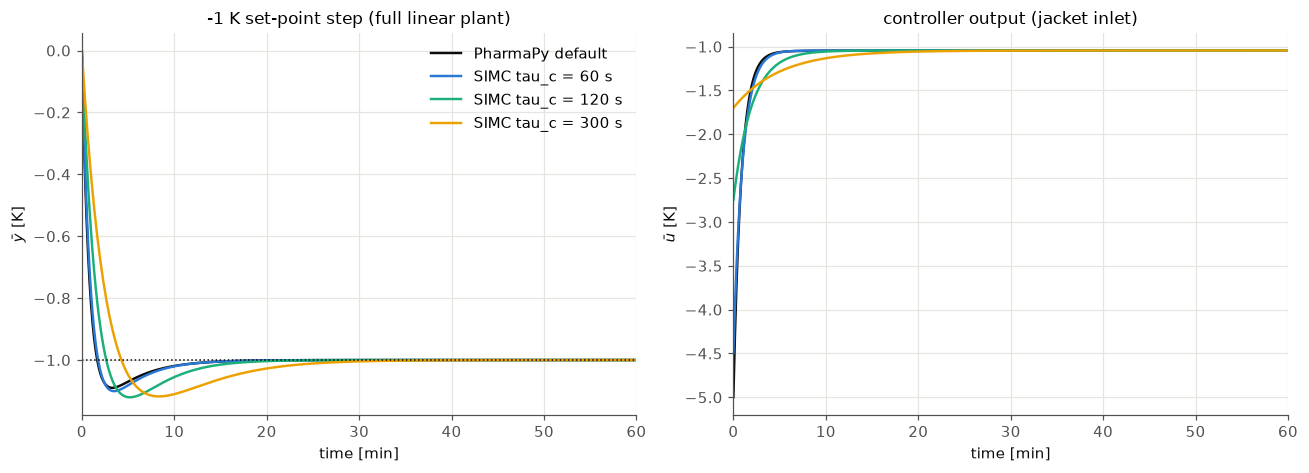

In [17]:
F = fits["FOPDT"]["p"]
tunings = {"PharmaPy default": (Kc, Ti)}
for tc_ in (60.0, 120.0, 300.0):
    kc = F["tau"] / (F["K"] * (tc_ + F["theta"]))
    tunings[f"SIMC tau_c = {tc_:.0f} s"] = (kc, min(F["tau"], 4 * (tc_ + F["theta"])))

tt2 = np.linspace(0, 3 * 3600, 1081)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
print(f"{'tuning':<20}{'Kc':>7}{'Ti [s]':>8}{'PM':>7}{'Ms':>7}{'overshoot':>10}{'IAE [K s]':>10}")
for (lab, (kc, ti)), col in zip(tunings.items(), (INK, BLUE, AQUA, YELLOW)):
    Acl_ = np.block([[A - kc * B @ C, (kc / ti) * B], [-C, np.zeros((1, 1))]])
    Bcl_ = np.vstack([(1 + kc) * B, [[1.0]]])
    _, y_, x_ = signal.lsim(signal.StateSpace(Acl_, Bcl_, Ccl, 0), -np.ones_like(tt2), tt2)
    u_ = -(1 + kc) - kc * y_ + (kc / ti) * x_[:, -1]
    m = margins(freq_full(A, B, C, wN) * kc * (ti * 1j * wN + 1) / (ti * 1j * wN), wN)
    os_ = max(0.0, -(y_.min() + 1))
    print(f"{lab:<20}{kc:>7.2f}{ti:>8.0f}{m['pm']:>6.0f}°{m['ms']:>7.2f}{os_:>10.1%}"
          f"{np.trapezoid(np.abs(y_ + 1), tt2):>10.0f}")
    ax[0].plot(tt2 / 60, y_, color=col, lw=1.6, label=lab)
    ax[1].plot(tt2 / 60, u_, color=col, lw=1.6)
ax[0].axhline(-1, color=INK, lw=1, ls=":")
ax[0].set_xlim(0, 60); ax[1].set_xlim(0, 60)
ax[0].set_ylabel(r"$\bar y$ [K]"); ax[1].set_ylabel(r"$\bar u$ [K]")
for a in ax: a.set_xlabel("time [min]")
ax[0].legend(); ax[0].set_title("-1 K set-point step (full linear plant)")
ax[1].set_title("controller output (jacket inlet)")
fig.tight_layout()

For a first-order plant with no delay, SIMC with $\tau_c$ gives
$K_c = \tau / (K\tau_c)$ and $T_i = \tau$. That is the same pole-zero
cancellation as PharmaPy's default, which corresponds to SIMC with
$\tau_c \approx \tau_{ht}/4 \approx 54$ s. All the tunings therefore
have PM ≈ 90° and differ only in speed. A larger $\tau_c$ means a slower
loop and a gentler jacket move (smaller $\bar u$ peak), at the cost of a
larger IAE. Overshoot rises slightly as $K_c$ falls, because the fixed
set-point feedforward then makes up a larger share of the initial move.

## 6. A second output: crystal yield

Temperature is what the jacket controls directly, but what matters for the
product is how much D, E and J crystallizes. Here the same step test is
read with a different output, $y_2$ = fraction of E crystallized. The fit
uses the same model set. Crystallization responds through solubility
(about 3 %/K) and through the crystal population, which turns over on the
residence-time scale, so this plant is much slower.

E: best by AIC = Lead-lag: K = -6.031, tau1 = 5162, tau2 = 221, tau_a = 1917   (K in percentage points per K)


D: best by AIC = Lead-lag: K = 5.026, tau1 = 3953, tau2 = 217.5, tau_a = -1890   (K in percentage points per K)


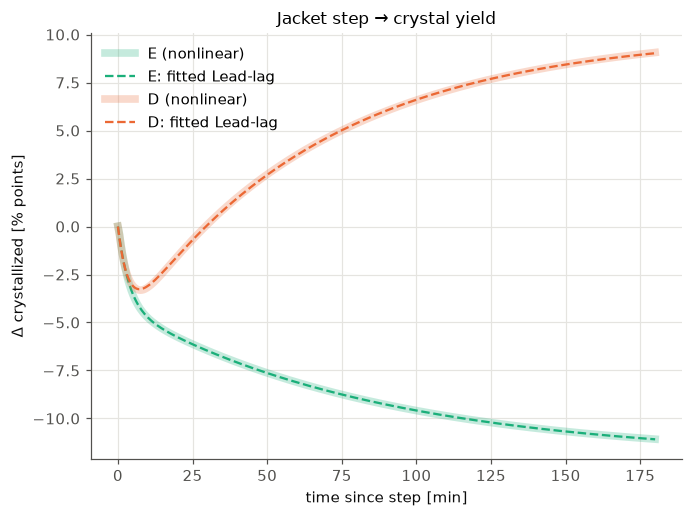

In [18]:
for sp, col in (("E", AQUA), ("D", ORANGE)):
    y2 = 100 * (step[f"frac_{sp}"][i1:i2 + 1] - step[f"frac_{sp}"][i1 - 1])
    best2, out2 = None, {}
    for name in ("FO", "SOPDT", "Lead-lag"):
        pnames, build = MODELS[name]
        g = {"FO": [y2[-1] / du, 1800], "SOPDT": [y2[-1] / du, 3000, 300, 0],
             "Lead-lag": [y2[-1] / du, 3000, 300, 100]}[name]
        lo, hi = zip(*(BOUNDS[p] if p != "K" else (-100, 100) for p in pnames))
        rr = optimize.least_squares(lambda p: step_response(*build(*p), tid, du) - y2,
                                    g, bounds=(lo, hi), x_scale="jac")
        sse = float(np.sum(rr.fun ** 2))
        out2[name] = (rr.x, tid.size * np.log(sse / tid.size) + 2 * len(pnames))
    best2 = min(out2, key=lambda k: out2[k][1])
    p2 = dict(zip(MODELS[best2][0], out2[best2][0]))
    print(f"{sp}: best by AIC = {best2}: " + ", ".join(f"{k} = {v:.4g}" for k, v in p2.items())
          + "   (K in percentage points per K)")
    plt.plot(tid / 60, y2, color=col, lw=5, alpha=0.25, label=f"{sp} (nonlinear)")
    plt.plot(tid / 60, step_response(*MODELS[best2][1](*out2[best2][0]), tid, du),
             color=col, lw=1.5, ls="--", label=f"{sp}: fitted {best2}")
plt.xlabel("time since step [min]"); plt.ylabel("Δ crystallized [% points]")
plt.title("Jacket step → crystal yield"); plt.legend()
plt.tight_layout()

**Two very different responses to the same +2 K jacket step:**
- **E** crystallizes less. Warmer liquid dissolves more of it
  (solubility rises ~3 %/K), and the population relaxes on the
  residence-time scale.
- **D** shows an **inverse response**: it first drops, like E, then rises
  to a higher yield. The reaction that makes D is the only one with a
  positive activation energy, so warming speeds up D production. After a
  delay this raises D's supersaturation by more than the solubility rise
  lowered it. In $G(s)$ this is a zero in the right half-plane
  ($\tau_a < 0$, at $s = +1/|\tau_a|$). That makes the plant
  **non-minimum phase**, which fundamentally limits how fast any controller
  can push D's yield. A common rule caps the closed-loop bandwidth at about
  $|z|/2$, roughly a 1 h time constant here.

## Summary

- **Stability.** CR02R is open-loop stable at its operating point for
  everything the jacket can reach. The 9 slightly unstable eigenvalues of
  the 818-state Jacobian sit on the crystal-size fronts. They come from the
  not-quite-steady point and the van Leer limiter, and they are about
  $10^{-7}$ less controllable and observable than the temperature mode.
- **The jacket-to-temperature plant is first order.**
  - $G(s) \approx 0.958 / (201 s + 1)$, with no dead time.
  - The time constant matches $K\,m c_p/(UA)$ to 3 %, the temperature row of
    the Jacobian (200.4 s) and the dominant PBH mode (200.5 s).
  - A lead-lag model adds a nearly cancelling slow pole and zero (about
    0.1 % of the gain).
  - On the −4 K validation step every model is within about 5 mK, which is
    the size of the plant's nonlinearity (gain 0.9587 vs 0.9571).
- **PharmaPy's default PI loop is IMC tuning.** Its zero cancels the plant
  pole, so $L \approx \omega_c/s$, with PM ≈ 90°, GM = ∞, $M_s$ = 1 and an
  84 s delay margin. The ~9 % overshoot comes from the set-point
  feedforward, not from the loop.
- **The linear closed-loop prediction matches the nonlinear PharmaPy run**
  on a −1 K step: same overshoot (8.9 %) and the same 10 min settling.
- **Crystal yield is a harder plant.** It is slow, and for D it is
  non-minimum phase. Controlling yield directly (for example cascade:
  yield → temperature set point → jacket) would have to respect that
  right-half-plane zero.